# Autoencoder riêng từng thiết bị

**Notebook này làm gì, nói đơn giản:** với mỗi thiết bị trong 9 thiết bị IoT, dạy một Autoencoder chỉ bằng lưu lượng *bình thường* của thiết bị đó.
Gặp lưu lượng mà mô hình "tái tạo" kém (lỗi lớn) thì coi là bất thường. Sau đó chọn một **ngưỡng** để quyết định lỗi lớn đến đâu thì báo động,
rồi đo bắt được bao nhiêu tấn công và báo nhầm bao nhiêu.

Notebook chỉ làm **Autoencoder**. Isolation Forest và VAE làm ở các notebook riêng, dùng lại đúng cách chia dữ liệu và đúng phần đánh giá
(mục II.3, II.4 và mục V). Chỉ cần đổi cách chấm điểm, các phần còn lại giữ nguyên.

## Các từ hay gặp

| Từ | Nghĩa |
| --- | --- |
| **Bắt được** (recall) | Trong 100 dòng tấn công, mô hình báo đúng bao nhiêu dòng |
| **Báo nhầm** (FPR) | Trong 100 dòng bình thường, mô hình báo nhầm bao nhiêu dòng |
| **Báo đúng khi cảnh báo** (precision) | Khi mô hình báo "tấn công", bao nhiêu phần trăm là đúng. Quy về tỷ lệ tấn công 5% như thực tế |
| **F1** | Điểm gộp giữa bắt được và báo đúng, từ 0 đến 1, càng cao càng tốt |
| **Ngưỡng** | Mức lỗi tái tạo tối thiểu để báo động |
| **Cửa sổ** | Một nhóm dòng liên tiếp. Cách của paper: báo tấn công khi quá nửa số dòng trong nhóm bị báo |
| **val / test** | `val` dùng để chọn ngưỡng. `test` chỉ dùng để báo cáo kết quả, không dùng chọn gì |

## Cách chia dữ liệu

| Loại dòng | Chia thế nào |
| --- | --- |
| Benign (bình thường) | Từng thiết bị, theo thời gian: 1/3 đầu là `train`, 1/3 giữa là `val`, 1/3 cuối là `test` |
| Tấn công | Mỗi file tấn công chia đôi theo thời gian: nửa đầu vào `val` (để chọn ngưỡng), nửa sau vào `test` (để báo cáo). Việc chia đôi làm ngay trong notebook này, ở mục V.1 |

## Mục lục

| Mục | Nội dung |
| --- | --- |
| **I** | Cấu hình |
| **II** | Hàm dùng chung |
| **III** | Kiểm tra dữ liệu đầu vào |
| **IV** | Huấn luyện 9 Autoencoder |
| **V** | Đánh giá: chọn ngưỡng, bảng và biểu đồ |
| **VI** | Tóm tắt và hạn chế |

**Điều kiện chạy:** bật GPU, Add Input output của notebook 01 (có thư mục `nbaiot_paper`).
**Chạy thử nhanh:** đặt biến môi trường `NBAIOT_DEVICES=1,3` và `AE_EPOCHS=30` trước khi chạy.

## I. Cấu hình

### 1. Thư viện và hàm in bảng

Hàm `show` in bảng cho dễ nhìn: số nguyên có dấu phẩy, số thực làm tròn, có thể đổi sang dạng phần trăm và tô màu (xanh là giá trị cao).

In [1]:
import os, glob, json, time, random, copy
import numpy as np, pandas as pd, pyarrow.dataset as ds, joblib
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def note(text):
    """In một đoạn chữ định dạng Markdown."""
    display(Markdown(text))

def show(df, pct=None, digits=3, fmt=None, grad=None, cmap="RdYlGn", vmin=None, vmax=None, caption=None):
    """In bảng dễ nhìn.
    pct  : True (mọi cột số thực hiện dạng %) hoặc danh sách tên cột hiện dạng %.
    fmt  : định dạng riêng cho số thực, ví dụ "{:.3g}".
    grad : True (tô màu mọi cột số thực) hoặc danh sách cột cần tô màu.
    Nếu môi trường không hỗ trợ thì tự in bảng chữ thường."""
    try:
        fm = {}
        for c in df.columns:
            dt = df[c].dtype
            if pd.api.types.is_bool_dtype(dt):
                continue
            if pd.api.types.is_integer_dtype(dt):
                fm[c] = "{:,}"
            elif pd.api.types.is_float_dtype(dt):
                is_pct = pct is True or (isinstance(pct, (list, tuple, set)) and c in pct)
                fm[c] = "{:.1%}" if is_pct else (fmt or "{:." + str(digits) + "f}")
        sty = df.style.format(fm, na_rep="-")
        if grad:
            cols = [c for c in df.columns if pd.api.types.is_float_dtype(df[c].dtype)] if grad is True else list(grad)
            if cols:
                sty = sty.background_gradient(cmap=cmap, subset=cols, vmin=vmin, vmax=vmax)
        if caption:
            sty = sty.set_caption(caption)
        display(HTML(sty.to_html()))
    except Exception:
        if caption:
            print(caption)
        print(df.to_string())

### 2. Tham số

Chỉnh tham số ở ô này. Hai dòng đầu (`MODEL_NAME`, `MODEL_TITLE`) là tên dùng cho file kết quả: notebook Isolation Forest và VAE chỉ cần đổi hai dòng này.

In [2]:
MODEL_NAME, MODEL_TITLE = "ae", "Autoencoder"

# ---- Huấn luyện (theo paper) ----
SEED = 42
HIDDEN_FRAC = (0.75, 0.50, 0.33, 0.25)    # 115 -> 86 -> 58 -> 38 -> 29 -> 38 -> 58 -> 86 -> 115
LR_GRID = (1e-3, 3e-3)                     # thử từng learning rate, giữ cái cho loss benign val thấp hơn
EPOCHS_MAX = int(os.environ.get("AE_EPOCHS", 300)) #thay đổi epoch
PATIENCE = 15                              # dừng sớm: loss val không giảm thêm 0,1% sau chừng này epoch
BATCH = 512

# ---- Đánh giá ----
ATTACK_RATIO = 0.05                        # quy precision và F1 về tỷ lệ tấn công 5% (mục 3 đề cương)
PI = ATTACK_RATIO
WS_MAX = 200                               # cỡ cửa sổ tối đa khi tìm cỡ nhỏ nhất cho 0% báo nhầm trên val (paper: 20 đến 82)
GRID = np.r_[np.arange(50, 99, 0.5), np.arange(99, 99.9, 0.1), 99.9, 99.95, 99.99]   # lưới ngưỡng thử (percentile của benign val)
AUC_MAX_ATTACK = 200_000                   # lấy mẫu tối đa khi tính AUC cho nhóm tấn công rất lớn

RULES = ["mean_std", "p99", "p95", "p90", "mad_3", "f1_opt"]
RULE_LABEL = {"mean_std": "mean+std (paper)", "p99": "percentile 99", "p95": "percentile 95",
              "p90": "percentile 90", "mad_3": "median+3·MAD", "f1_opt": "F1 tối ưu (dùng nhãn val)"}
MAIN_RULE = "f1_opt"                       # quy tắc dùng làm kết quả chính ở mục VI
TCP_UDP = ["gafgyt_tcp", "gafgyt_udp"]     # hai loại tấn công bị bỏ sót ở vòng 1
DEV_PLOT = [1, 5]                          # thiết bị vẽ phân phối điểm ở mục V.6

# ---- Đường dẫn ----
WORK = os.environ.get("NBAIOT_WORK", "/kaggle/working")
BASE = os.environ.get("NBAIOT_DATASET")
if not BASE:
    found = [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/nbaiot_paper", recursive=True)]
    assert found, "Không thấy nbaiot_paper: chạy notebook 01 (mục chia theo thời gian) rồi Add Input output của nó"
    BASE = found[0]
PAPER_DIR = f"{BASE}/nbaiot_paper"
OUT, MODELS, SCORES = f"{WORK}/results", f"{WORK}/models/{MODEL_NAME}", f"{WORK}/scores"
for p in (OUT, MODELS, SCORES):
    os.makedirs(p, exist_ok=True)
FEAT = json.load(open(f"{BASE}/manifest_paper.json", encoding="utf-8"))["feature_columns"]

dev_all = sorted(int(d.split("=")[1]) for d in os.listdir(PAPER_DIR) if d.startswith("device_id="))
DEVICES = [int(x) for x in os.environ["NBAIOT_DEVICES"].split(",")] if os.environ.get("NBAIOT_DEVICES") else dev_all
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

cfg = pd.DataFrame({"Giá trị": [
    BASE, str(DEVICES), str(len(FEAT)),
    f"{torch.__version__} | " + (torch.cuda.get_device_name(0) if DEVICE == "cuda" else "KHÔNG có GPU (vẫn chạy được, chậm hơn)"),
    f"tối đa {EPOCHS_MAX} (dừng sớm sau {PATIENCE})", str(LR_GRID), str(HIDDEN_FRAC), str(SEED)]},
    index=["Dataset", "Thiết bị sẽ chạy", "Số đặc trưng", "torch / thiết bị tính toán", "Số epoch",
           "Learning rate thử", "Tỷ lệ lớp ẩn so với đầu vào", "Seed"])
show(cfg, caption="I.2 Cấu hình của lần chạy này")

,Giá trị
Dataset,/kaggle/input/notebooks/hienpro0123/01-data-spark/processed
Thiết bị sẽ chạy,"[1, 2, 3, 4, 5, 6, 7, 8, 9]"
Số đặc trưng,115
torch / thiết bị tính toán,2.11.0+cu130 | Tesla T4
Số epoch,tối đa 300 (dừng sớm sau 15)
Learning rate thử,"(0.001, 0.003)"
Tỷ lệ lớp ẩn so với đầu vào,"(0.75, 0.5, 0.33, 0.25)"
Seed,42


## II. Hàm dùng chung

Bốn nhóm hàm, mỗi nhóm một ô. Các ô này chỉ định nghĩa hàm, chạy rất nhanh và không in gì.

### 1. Mô hình Autoencoder và huấn luyện

- Kiến trúc của paper: 4 lớp nén còn 75%, 50%, 33%, 25% kích thước đầu vào, rồi giãn ngược lại. Với 115 đặc trưng: 115 → 86 → 58 → 38 → 29 → 38 → 58 → 86 → 115.
- Mô hình học tái tạo lại đúng dữ liệu đầu vào. Lỗi tái tạo (MSE) của từng dòng chính là **điểm bất thường**: càng cao càng lạ.
- Thử hai learning rate và giữ cái cho loss val thấp hơn. Dừng sớm khi loss val không còn giảm.

In [3]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class AE(nn.Module):
    """Autoencoder của paper: 115 -> 75% -> 50% -> 33% -> 25% -> 33% -> 50% -> 75% -> 115."""
    def __init__(self, n_in, fracs=HIDDEN_FRAC):
        super().__init__()
        sizes = [n_in] + [max(2, int(round(n_in * f))) for f in fracs]
        layers = []
        for a, b in zip(sizes[:-1], sizes[1:]):                       # bộ mã hóa: nén dần
            layers += [nn.Linear(a, b), nn.ReLU()]
        r = sizes[::-1]
        for k, (a, b) in enumerate(zip(r[:-1], r[1:])):               # bộ giải mã: giãn dần, lớp cuối không ReLU
            layers.append(nn.Linear(a, b))
            if k < len(r) - 2:
                layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)
        self.sizes = sizes
    def forward(self, x):
        return self.net(x)

@torch.no_grad()
def recon_error(model, X, bs=65536):
    """Điểm bất thường từng dòng = lỗi tái tạo trung bình qua 115 đặc trưng. CAO = bất thường."""
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        out.append(((model(xb) - xb) ** 2).mean(1).cpu().numpy())
    return np.concatenate(out)

def train_one(Xtr, Xva, lr):
    """Huấn luyện một Autoencoder với learning rate lr. Trả về (mô hình tốt nhất, lịch sử, loss val tốt nhất)."""
    set_seed(SEED)
    m = AE(Xtr.shape[1]).to(DEVICE); opt = torch.optim.Adam(m.parameters(), lr=lr)
    Xt = torch.from_numpy(Xtr).to(DEVICE)
    best, bad, state, hist = float("inf"), 0, None, []
    for ep in range(EPOCHS_MAX):
        m.train(); perm = torch.randperm(len(Xt), device=DEVICE); tot = torch.zeros((), device=DEVICE)
        for i in range(0, len(Xt), BATCH):
            xb = Xt[perm[i:i + BATCH]]
            loss = ((m(xb) - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.detach() * len(xb)
        va = float(recon_error(m, Xva).mean())
        hist.append(dict(epoch=ep, train_loss=float(tot) / len(Xt), val_loss=va))
        if va < best * (1 - 1e-3):
            best, bad, state = va, 0, copy.deepcopy(m.state_dict())
        else:
            bad += 1
        if bad >= PATIENCE:
            break
    m.load_state_dict(state)
    return m, hist, best

def fit_ae(Xtr, Xva):
    """Thử từng learning rate trong LR_GRID, giữ cái cho loss val thấp nhất. Trả về (mô hình, lịch sử, loss val, lr)."""
    runs = [(*train_one(Xtr, Xva, lr), lr) for lr in LR_GRID]
    return min(runs, key=lambda r: r[2])

### 2. Đọc dữ liệu

- `load_device`: đọc toàn bộ dòng của một thiết bị, sắp theo (nhóm, `row_id`) để **giữ thứ tự thời gian trong từng nhóm**.
- `load_scores`: đọc lại điểm bất thường đã lưu ở mục IV.

In [4]:
def load_device(d):
    """Đọc dữ liệu một thiết bị. Trả về (bảng nhãn gồm cột kind và split, ma trận đặc trưng float32).
    kind: 'benign' hoặc '<họ>_<loại tấn công>'. Các dòng đã sắp theo (kind, row_id), tức theo thời gian trong từng nhóm."""
    tb = ds.dataset(PAPER_DIR, format="parquet", partitioning="hive").to_table(
        columns=FEAT + ["label", "family", "attack_type", "row_id", "split"], filter=ds.field("device_id") == d)
    df = tb.to_pandas()
    df["kind"] = np.where(df["label"].values == 1, (df["family"] + "_" + df["attack_type"]).values, "benign")
    df = df.sort_values(["kind", "row_id"], kind="stable").reset_index(drop=True)
    X = df[FEAT].to_numpy(np.float32)
    return df[["kind", "split"]].copy(), X

def load_scores(d):
    """Đọc điểm bất thường đã lưu của một thiết bị. Trả về (kind, split, điểm), cùng thứ tự với load_device."""
    path = f"{SCORES}/{MODEL_NAME}_dev{d}.npz"
    assert os.path.exists(path), f"Chưa có {path}: chạy mục IV (huấn luyện) trước"
    z = np.load(path)
    return z["kind_names"][z["kind_codes"]], z["split_names"][z["split_codes"]], z["score"]

### 3. Chọn ngưỡng và cửa sổ

Sáu quy tắc chọn ngưỡng, so sánh với nhau ở mục V:

| Quy tắc | Cách chọn | Dùng nhãn tấn công? |
| --- | --- | --- |
| `mean+std` | trung bình + độ lệch chuẩn của điểm benign val (paper) | không |
| `percentile 99 / 95 / 90` | báo nhầm khoảng 1% / 5% / 10% benign val | không |
| `median+3·MAD` | trung vị + 3 lần độ lệch tuyệt đối trung vị của benign val | không |
| `F1 tối ưu` | quét nhiều ngưỡng, chọn cái cho F1 cao nhất trên val (có cả benign và nửa val của tấn công) | **có** (bán giám sát) |

Với F1 tối ưu, recall là trung bình qua các loại tấn công (mỗi loại một trọng số, để tcp/udp không bị loãng bởi các loại lớn hơn).
Precision quy về tỷ lệ tấn công 5%.

In [5]:
def make_roles(kind, split):
    """Gán vai trò cho từng dòng:
       b_val / b_test : benign dùng để chọn ngưỡng / để báo cáo
       a_val / a_test : nửa đầu / nửa sau (theo thời gian) của từng file tấn công
       b_train        : benign dùng huấn luyện (không dùng khi đánh giá)"""
    role = np.where(kind == "benign",
                    np.where(split == "val", "b_val", np.where(split == "test", "b_test", "b_train")), "x").astype("U8")
    for k in sorted(set(kind) - {"benign"}):
        idx = np.flatnonzero(kind == k); h = len(idx) // 2          # kind đã sắp theo row_id nên idx theo thứ tự thời gian
        role[idx[:h]] = "a_val"; role[idx[h:]] = "a_test"
    return role

def benign_rules(s_val):
    """Các ngưỡng chỉ dùng điểm của benign val."""
    med = np.median(s_val); mad = np.median(np.abs(s_val - med)) * 1.4826
    return {"mean_std": float(s_val.mean() + s_val.std(ddof=1)),
            "p99": float(np.percentile(s_val, 99)), "p95": float(np.percentile(s_val, 95)),
            "p90": float(np.percentile(s_val, 90)), "mad_3": float(med + 3.0 * mad)}

def pick_threshold_f1(s, kind, role):
    """Ngưỡng cho F1 cao nhất trên val. Trả về (ngưỡng, thông tin trên val)."""
    att = sorted(set(kind) - {"benign"})
    b = np.sort(s[role == "b_val"])
    A = [np.sort(s[(kind == k) & (role == "a_val")]) for k in att]
    A = [a for a in A if len(a)]
    cand = np.unique(np.percentile(b, GRID))
    fpr = 1 - np.searchsorted(b, cand, side="right") / len(b)                                   # báo nhầm tại từng ngưỡng
    rec = np.mean([1 - np.searchsorted(a, cand, side="right") / len(a) for a in A], axis=0)     # bắt được (TB các loại)
    p = rec * PI / np.maximum(rec * PI + fpr * (1 - PI), 1e-12)
    f1 = 2 * p * rec / np.maximum(p + rec, 1e-12)
    i = np.lexsort((fpr, -np.round(f1, 6)))[0]                       # F1 cao nhất; hòa thì chọn báo nhầm thấp hơn
    return float(cand[i]), dict(val_bat_duoc=float(rec[i]), val_bao_nham=float(fpr[i]), val_f1=float(f1[i]))

def window_flags(flag, ws):
    """Bỏ phiếu đa số trên cửa sổ trượt (bước 1 dòng). flag: bool theo thứ tự thời gian.
    Trả về bool cho từng cửa sổ: True nếu quá nửa số dòng trong cửa sổ bị báo."""
    if len(flag) < ws:
        return np.zeros(0, dtype=bool)
    cs = np.concatenate([[0], np.cumsum(flag, dtype=np.int64)])
    return (cs[ws:] - cs[:-ws]) > ws / 2

def choose_ws(flag_val, ws_max=WS_MAX):
    """Cỡ cửa sổ nhỏ nhất cho 0% cửa sổ benign val bị báo nhầm (công thức 2 của paper).
    Trả về (cỡ cửa sổ, đã đạt 0% chưa). Chưa đạt nghĩa là chạm trần ws_max."""
    for ws in range(1, min(ws_max, len(flag_val)) + 1):
        wf = window_flags(flag_val, ws)
        if wf.size and not wf.any():
            return ws, True
    return min(ws_max, len(flag_val)), False

### 4. Chấm điểm một thiết bị và tổng hợp

- `evaluate_device`: cho một thiết bị, với mỗi quy tắc ngưỡng và mỗi loại tấn công, đếm số dòng bị báo và số cửa sổ bị báo. Mọi thứ tính trên **benign test** và **nửa test của tấn công**.
- `summarize`: gộp mọi thiết bị lại theo từng quy tắc ngưỡng.

In [6]:
def evaluate_device(d, s, kind, split, rng):
    """Đánh giá một thiết bị. Trả về (các dòng kết quả, AUC theo loại, ngưỡng, thông tin chọn ngưỡng F1)."""
    role = make_roles(kind, split)
    sv = s[role == "b_val"]
    thr = benign_rules(sv)
    thr["f1_opt"], info = pick_threshold_f1(s, kind, role)
    att_kinds = sorted(set(kind) - {"benign"})
    rows = []
    for rule in RULES:
        t = thr[rule]
        ws, ws_ok = choose_ws(sv > t)
        for k in ["benign"] + att_kinds:
            m = (role == "b_test") if k == "benign" else ((kind == k) & (role == "a_test"))
            f = s[m] > t; wf = window_flags(f, ws)
            rows.append(dict(device_id=d, rule=rule, thr=t, ws=ws, ws_ok=ws_ok, kind=k, n=int(m.sum()),
                             n_flag=int(f.sum()), row_rate=float(f.mean()),
                             window_rate=float(wf.mean()) if wf.size else np.nan, detected=bool(wf.any())))
    sb = s[role == "b_test"]
    aucs = []
    for k in att_kinds:                         # AUC: điểm có tách được tấn công khỏi benign không, không phụ thuộc ngưỡng
        sa = s[(kind == k) & (role == "a_test")]
        if len(sa) > AUC_MAX_ATTACK:
            sa = rng.choice(sa, AUC_MAX_ATTACK, replace=False)
        aucs.append(dict(device_id=d, kind=k,
                         auc=float(roc_auc_score(np.r_[np.zeros(len(sb)), np.ones(len(sa))], np.r_[sb, sa]))))
    return rows, aucs, thr, info

def summarize(L):
    """Tổng hợp mọi thiết bị theo từng quy tắc ngưỡng."""
    out = []
    for rule in RULES:
        g = L[L.rule == rule]
        att, ben = g[g.kind != "benign"], g[g.kind == "benign"]
        r = (att.n_flag / att.n).mean()                           # bắt được, trung bình qua các cặp (thiết bị, loại)
        f = ben.n_flag.sum() / ben.n.sum()                        # báo nhầm
        p = r * PI / max(r * PI + f * (1 - PI), 1e-12)            # báo đúng khi cảnh báo, ở tỷ lệ tấn công 5%
        tu = att[att.kind.isin(TCP_UDP)]
        out.append(dict(rule=rule, recall_macro=r, recall_tcp_udp=tu.n_flag.sum() / tu.n.sum(), fpr=f, precision=p,
                        f1=2 * p * r / max(p + r, 1e-12), n_missed=int((att.n_flag == 0).sum()), n_pairs=len(att)))
    return pd.DataFrame(out).set_index("rule")

## III. Kiểm tra dữ liệu đầu vào

### 1. Số dòng theo thiết bị

Bảng đếm số dòng của từng thiết bị theo từng loại dòng. Hai điều cần kiểm tra:
- `Benign train`, `Benign val`, `Benign test` xấp xỉ bằng nhau (mỗi loại khoảng 1/3 benign của thiết bị).
- Tổng cộng đủ **7.062.606** dòng nếu chạy cả 9 thiết bị.

In [7]:
tb = ds.dataset(PAPER_DIR, format="parquet", partitioning="hive").to_table(columns=["device_id", "split", "label"]).to_pandas()
tb["nhom"] = np.where(tb["label"] == 1, "Tấn công (toàn bộ)", "Benign " + tb["split"].astype(str))
cnt = tb.groupby(["device_id", "nhom"]).size().unstack(fill_value=0)
cnt = cnt[["Benign train", "Benign val", "Benign test", "Tấn công (toàn bộ)"]]
cnt["Tổng"] = cnt.sum(axis=1)
cnt.loc["Cộng"] = cnt.sum()
cnt.index.name = "Thiết bị"
show(cnt, caption="III.1 Số dòng theo thiết bị và loại dòng")

tong = int(cnt.loc["Cộng", "Tổng"])
if DEVICES == dev_all and len(dev_all) == 9:
    print(("ĐẠT" if tong == 7062606 else "LỆCH") + f": tổng {tong:,} dòng (UCI công bố 7.062.606)")
else:
    print(f"Chạy {len(DEVICES)} thiết bị, tổng {tong:,} dòng.")
del tb

nhom,Benign train,Benign val,Benign test,Tấn công (toàn bộ),Tổng
Thiết bị,,,,,
1,"16,516","16,516","16,516","968,750","1,018,298"
2,"4,371","4,371","4,371","822,763","835,876"
3,"13,033","13,033","13,034","316,400","355,500"
4,"58,413","58,413","58,414","923,437","1,098,677"
5,"20,718","20,718","20,718","766,106","828,260"
6,"32,838","32,838","32,838","738,377","836,891"
7,"17,383","17,383","17,384","323,072","375,222"
8,"15,528","15,528","15,529","816,471","863,056"
9,"6,509","6,509","6,510","831,298","850,826"


ĐẠT: tổng 7,062,606 dòng (UCI công bố 7.062.606)


## IV. Huấn luyện 9 Autoencoder

### 1. Huấn luyện từng thiết bị

Với mỗi thiết bị:
1. Đọc dữ liệu, chuẩn hóa bằng scaler **chỉ tính trên benign train** của thiết bị đó.
2. Huấn luyện Autoencoder (thử hai learning rate, dừng sớm).
3. Chấm điểm bất thường cho **mọi dòng** rồi lưu lại, để mục V đánh giá mà không cần huấn luyện lại.

Mỗi thiết bị in một dòng khi xong. Cột `Loss val` là lỗi tái tạo trung bình trên benign val, càng nhỏ càng tốt.

In [8]:
TIMING, LOG = [], []
print(f"{'Thiết bị':>8} | {'Dòng train':>10} | {'Epoch':>5} | {'LR':>6} | {'Loss val':>9} | {'Giây':>5}")
print("-" * 60)
for d in DEVICES:
    t0 = time.time()
    meta, X = load_device(d)
    kind = meta["kind"].to_numpy().astype("U32"); split = meta["split"].to_numpy().astype("U8")
    m_tr = (kind == "benign") & (split == "train"); m_va = (kind == "benign") & (split == "val")

    scaler = StandardScaler().fit(X[m_tr])                           # chỉ fit trên benign train của thiết bị này
    Xs = scaler.transform(X).astype(np.float32, copy=False)
    model, hist, best_val, lr = fit_ae(Xs[m_tr], Xs[m_va])
    score = recon_error(model, Xs)                                   # điểm bất thường của mọi dòng

    # lưu mô hình, scaler và điểm số
    torch.save(model.state_dict(), f"{MODELS}/{MODEL_NAME}_dev{d}.pt")
    joblib.dump(scaler, f"{MODELS}/scaler_dev{d}.joblib")
    kn, kc = np.unique(kind, return_inverse=True); sn, sc = np.unique(split, return_inverse=True)
    np.savez_compressed(f"{SCORES}/{MODEL_NAME}_dev{d}.npz", kind_names=kn, kind_codes=kc.astype(np.int8),
                        split_names=sn, split_codes=sc.astype(np.int8), score=score.astype(np.float32))

    LOG += [dict(device_id=d, lr=lr, **h) for h in hist]
    TIMING.append(dict(device_id=d, n_train=int(m_tr.sum()), n_val=int(m_va.sum()), n_total=len(kind), lr=lr,
                       epochs=len(hist), val_loss=best_val, seconds=time.time() - t0))
    print(f"{d:>8} | {int(m_tr.sum()):>10,} | {len(hist):>5} | {lr:>6} | {best_val:>9.4f} | {time.time() - t0:>5.0f}")
    del X, Xs, meta
print("\nĐã lưu mô hình vào", MODELS, "và điểm số vào", SCORES)

Thiết bị | Dòng train | Epoch |     LR |  Loss val |  Giây
------------------------------------------------------------
       1 |     16,516 |   225 |  0.001 |    0.0306 |    52
       2 |      4,371 |   300 |  0.001 |    0.0343 |    29
       3 |     13,033 |    49 |  0.003 |    0.6554 |     7
       4 |     58,413 |   237 |  0.001 |    0.0057 |   168
       5 |     20,718 |   297 |  0.001 |    0.0061 |    57
       6 |     32,838 |   184 |  0.001 |    0.0454 |    83
       7 |     17,383 |   170 |  0.001 |    0.0363 |    30
       8 |     15,528 |   118 |  0.001 |    0.0181 |    33
       9 |      6,509 |   101 |  0.003 |    0.6920 |    24

Đã lưu mô hình vào /kaggle/working/models/ae và điểm số vào /kaggle/working/scores


### 2. Tóm tắt huấn luyện

Nếu một thiết bị có `Loss val` cao hơn hẳn các thiết bị khác, mô hình của thiết bị đó có thể chưa học tốt. Ô dưới tự đánh dấu những thiết bị có loss val lớn hơn 5 lần trung vị.

In [9]:
TIM = pd.DataFrame(TIMING)
TIM.to_csv(f"{OUT}/{MODEL_NAME}_huan_luyen.csv", index=False)
pd.DataFrame(LOG).to_csv(f"{OUT}/{MODEL_NAME}_loss_log.csv", index=False)

view = TIM.rename(columns={"device_id": "Thiết bị", "n_train": "Dòng train", "n_val": "Dòng val", "n_total": "Tổng dòng",
                           "lr": "Learning rate", "epochs": "Số epoch", "val_loss": "Loss val tốt nhất",
                           "seconds": "Giây"}).set_index("Thiết bị")
show(view, digits=4, caption="IV.2 Tóm tắt huấn luyện từng thiết bị")

odd = TIM.loc[TIM.val_loss > 5 * TIM.val_loss.median(), "device_id"].tolist()
if odd:
    note(f"**Lưu ý:** thiết bị **{', '.join(map(str, odd))}** có loss val lớn hơn 5 lần trung vị. Nên xem lại đường cong loss ở mục IV.3 và các con số của thiết bị này ở mục V.")
else:
    note("Không có thiết bị nào có loss val lớn bất thường.")

,Dòng train,Dòng val,Tổng dòng,Learning rate,Số epoch,Loss val tốt nhất,Giây
Thiết bị,,,,,,,
1,"16,516","16,516","1,018,298",0.0010,225,0.0306,51.7649
2,"4,371","4,371","835,876",0.0010,300,0.0343,28.7763
3,"13,033","13,033","355,500",0.0030,49,0.6554,7.1928
4,"58,413","58,413","1,098,677",0.0010,237,0.0057,167.8179
5,"20,718","20,718","828,260",0.0010,297,0.0061,56.7022
6,"32,838","32,838","836,891",0.0010,184,0.0454,83.4030
7,"17,383","17,383","375,222",0.0010,170,0.0363,29.6099
8,"15,528","15,528","863,056",0.0010,118,0.0181,32.8673
9,"6,509","6,509","850,826",0.0030,101,0.6920,23.9808


**Lưu ý:** thiết bị **3, 9** có loss val lớn hơn 5 lần trung vị. Nên xem lại đường cong loss ở mục IV.3 và các con số của thiết bị này ở mục V.

### 3. Đường cong loss

Mỗi ô nhỏ là một thiết bị. Đường `train` và `val` nên cùng đi xuống và gần nhau. Nếu `val` cao hơn hẳn `train`, dữ liệu val khác dữ liệu train (có thể do thay đổi theo thời gian).

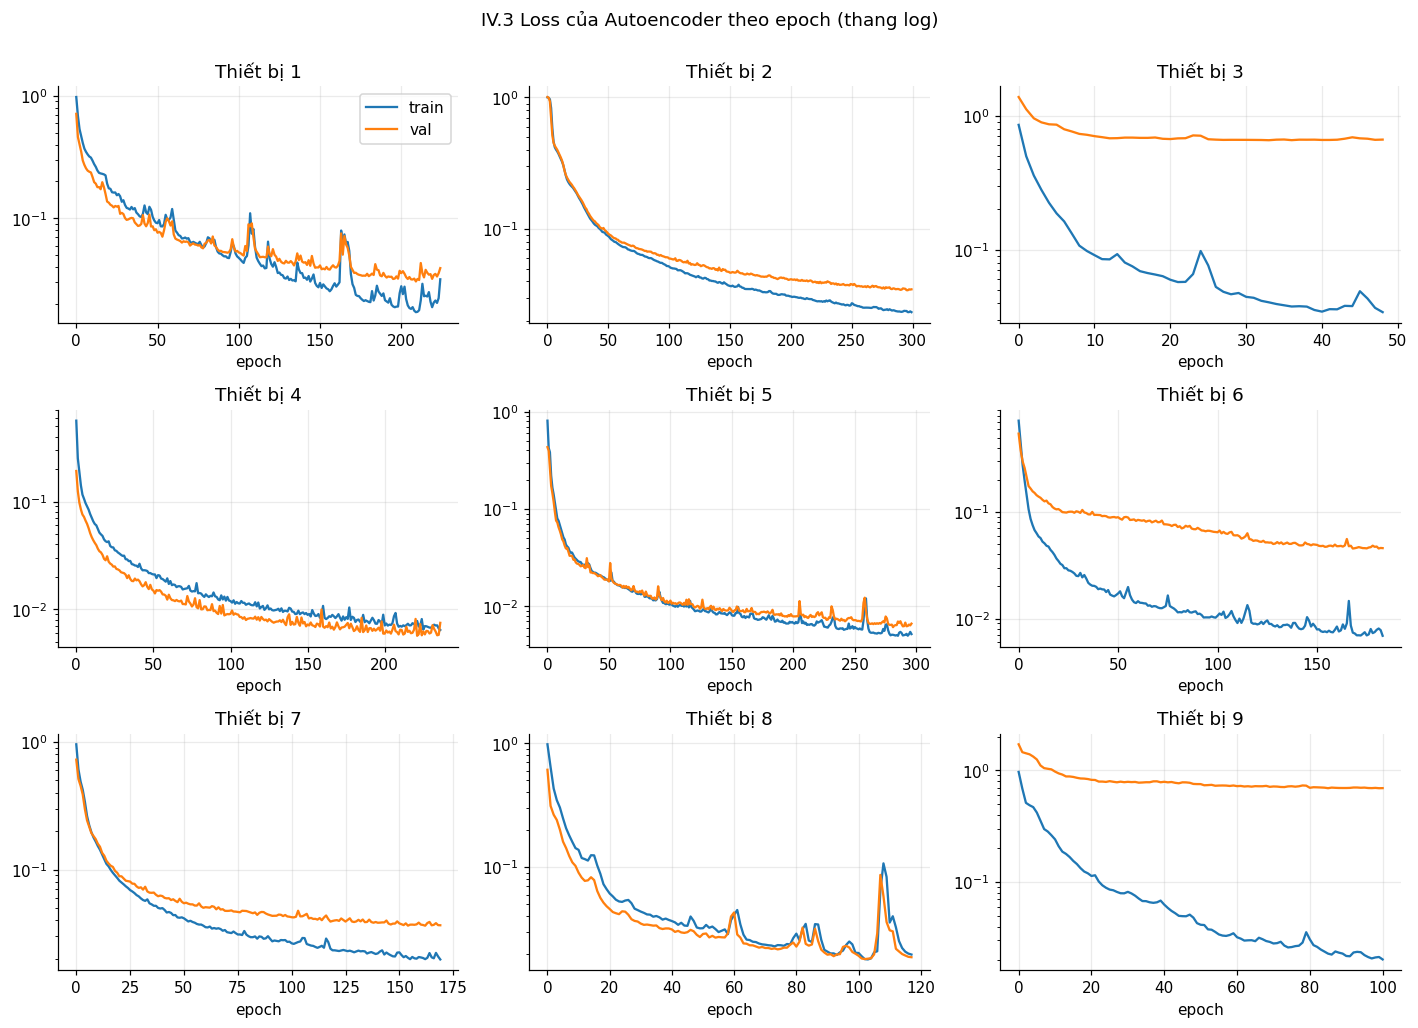

In [10]:
LOGD = pd.DataFrame(LOG)
n = len(DEVICES); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.1 * nrow), squeeze=False)
for ax, d in zip(axes.ravel(), DEVICES):
    g = LOGD[LOGD.device_id == d]
    ax.plot(g.epoch, g.train_loss, label="train"); ax.plot(g.epoch, g.val_loss, label="val")
    ax.set_yscale("log"); ax.set_title(f"Thiết bị {d}"); ax.set_xlabel("epoch")
axes.ravel()[0].legend()
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("IV.3 Loss của Autoencoder theo epoch (thang log)", y=1.0)
fig.tight_layout(); fig.savefig(f"{OUT}/{MODEL_NAME}_loss_curve.png", dpi=150); plt.show()

## V. Đánh giá

### 1. Chấm điểm và chọn ngưỡng

Với mỗi thiết bị: đọc điểm đã lưu, chia tấn công thành nửa `val` và nửa `test` theo thời gian, chọn ngưỡng theo cả sáu quy tắc, rồi đếm kết quả trên phần `test`.

Hai bảng in ra:
- **V.1a** là ngưỡng của từng thiết bị theo từng quy tắc.
- **V.1b** là kết quả chọn ngưỡng `F1 tối ưu` trên `val`: bắt được, báo nhầm và F1 mà ngưỡng đó đạt được **trên val** (chưa phải kết quả test).

In [11]:
rng = np.random.default_rng(SEED)
ROWS, AUCS, SEL = [], [], []
for d in DEVICES:
    kind, split, s = load_scores(d)
    rows, aucs, thr, info = evaluate_device(d, s, kind, split, rng)
    ROWS += rows; AUCS += aucs; SEL.append(dict(device_id=d, **info))
L, AUC, SELD = pd.DataFrame(ROWS), pd.DataFrame(AUCS), pd.DataFrame(SEL)
L.to_csv(f"{OUT}/{MODEL_NAME}_chi_tiet.csv", index=False); AUC.to_csv(f"{OUT}/{MODEL_NAME}_auc.csv", index=False)

# V.1a ngưỡng từng thiết bị
T = L.drop_duplicates(["device_id", "rule"]).pivot(index="device_id", columns="rule", values="thr")[RULES]
T.columns = [RULE_LABEL[r] for r in RULES]; T.index.name = "Thiết bị"
show(T, fmt="{:.3g}", caption="V.1a Ngưỡng của từng thiết bị (điểm bất thường lớn hơn ngưỡng thì báo)")

# V.1b kết quả chọn ngưỡng F1 tối ưu trên val
S = SELD.rename(columns={"device_id": "Thiết bị", "val_bat_duoc": "Bắt được (val)", "val_bao_nham": "Báo nhầm (val)",
                         "val_f1": "F1 (val)"}).set_index("Thiết bị")
show(S, pct=["Bắt được (val)", "Báo nhầm (val)"], digits=3, caption="V.1b Kết quả của ngưỡng F1 tối ưu, tính trên val")

,mean+std (paper),percentile 99,percentile 95,percentile 90,median+3·MAD,F1 tối ưu (dùng nhãn val)
Thiết bị,,,,,,
1,0.664,0.298,0.0457,0.0212,0.00877,0.472
2,0.164,0.453,0.125,0.059,0.0355,2.58
3,17,0.939,0.116,0.0672,0.0348,0.175
4,0.124,0.113,0.0122,0.00406,0.00206,0.129
5,0.0393,0.0639,0.0191,0.0111,0.00723,1.56
6,0.156,0.516,0.27,0.168,0.0201,1.63
7,0.29,0.589,0.146,0.0217,0.00856,7.12
8,0.208,0.206,0.0459,0.0211,0.0115,3.02
9,8.22,14.8,0.241,0.0571,0.00473,225


,Bắt được (val),Báo nhầm (val),F1 (val)
Thiết bị,,,
1,100.0%,0.6%,0.946
2,80.0%,0.0%,0.887
3,100.0%,2.5%,0.808
4,100.0%,0.8%,0.929
5,80.0%,0.0%,0.887
6,80.0%,0.0%,0.888
7,60.0%,0.0%,0.749
8,79.5%,0.1%,0.881
9,79.4%,0.0%,0.884


### 2. Bảng tổng hợp theo quy tắc ngưỡng

Đây là bảng quan trọng nhất. Mỗi hàng là một quy tắc chọn ngưỡng, tính trên phần `test`, gộp 9 thiết bị:

| Cột | Ý nghĩa |
| --- | --- |
| Bắt được (TB các loại) | Tỷ lệ bắt được, trung bình qua từng cặp (thiết bị, loại tấn công) |
| Bắt tcp/udp | Tỷ lệ bắt được riêng hai loại `gafgyt_tcp` và `gafgyt_udp` |
| Báo nhầm | Tỷ lệ benign bị báo nhầm |
| Báo đúng khi cảnh báo | Precision ở tỷ lệ tấn công 5% |
| F1 | Điểm gộp, càng cao càng tốt |
| Cặp bỏ sót hoàn toàn | Số cặp (thiết bị, loại) mà không dòng nào bị báo |

Cần đọc cả bốn cột chính cùng lúc: bắt được nhiều mà báo nhầm cũng nhiều thì không dùng được.

In [12]:
SUM = summarize(L)
V = SUM.rename(columns={"recall_macro": "Bắt được (TB các loại)", "recall_tcp_udp": "Bắt tcp/udp", "fpr": "Báo nhầm",
                        "precision": "Báo đúng khi cảnh báo", "f1": "F1",
                        "n_missed": "Cặp bỏ sót hoàn toàn", "n_pairs": "Tổng cặp"})
V.index = [RULE_LABEL[r] for r in V.index]; V.index.name = "Quy tắc ngưỡng"
V.to_csv(f"{OUT}/{MODEL_NAME}_tong_hop.csv")
show(V, pct=["Bắt được (TB các loại)", "Bắt tcp/udp", "Báo nhầm", "Báo đúng khi cảnh báo"],
     grad=["Bắt được (TB các loại)", "Bắt tcp/udp", "Báo đúng khi cảnh báo", "F1"], vmin=0, vmax=1,
     caption="V.2 Kết quả trên test theo quy tắc ngưỡng (gộp 9 thiết bị)")

,Bắt được (TB các loại),Bắt tcp/udp,Báo nhầm,Báo đúng khi cảnh báo,F1,Cặp bỏ sót hoàn toàn,Tổng cặp
Quy tắc ngưỡng,,,,,,,
mean+std (paper),80.0%,11.1%,2.0%,67.5%,0.732,0,80
percentile 99,82.5%,22.0%,1.1%,80.4%,0.814,0,80
percentile 95,90.0%,55.6%,5.4%,46.9%,0.616,0,80
percentile 90,92.5%,67.1%,11.4%,29.9%,0.452,0,80
median+3·MAD,100.0%,100.0%,20.8%,20.2%,0.336,0,80
F1 tối ưu (dùng nhãn val),85.0%,33.3%,0.6%,87.4%,0.862,3,80


### 3. Kết quả theo loại tấn công

Mỗi ô là tỷ lệ bắt được của một loại tấn công, gộp 9 thiết bị, theo từng quy tắc ngưỡng. Xanh là bắt tốt, đỏ là bỏ sót.
Hàng `benign` ở bảng nhỏ phía dưới là tỷ lệ báo nhầm, nên **càng thấp càng tốt**.

In [13]:
g = L.groupby(["kind", "rule"]).agg(n=("n", "sum"), f=("n_flag", "sum")).reset_index()
g["tl"] = g.f / g.n
K = g.pivot(index="kind", columns="rule", values="tl")[RULES]
cols = [RULE_LABEL[r] for r in RULES]
K.columns = cols
K.insert(0, "Số dòng test", g[g.rule == "p99"].set_index("kind")["n"])
K.index.name = "Loại"
K.to_csv(f"{OUT}/{MODEL_NAME}_theo_loai.csv")

show(K.drop(index="benign"), pct=cols, grad=cols, vmin=0, vmax=1, caption="V.3a Tỷ lệ bắt được theo loại tấn công")
show(K.loc[["benign"], cols], pct=True, grad=True, cmap="RdYlGn_r", vmin=0, vmax=0.25,
     caption="V.3b Tỷ lệ báo nhầm trên benign test")

,Số dòng test,mean+std (paper),percentile 99,percentile 95,percentile 90,median+3·MAD,F1 tối ưu (dùng nhãn val)
Loại,,,,,,,
gafgyt_combo,"257,579",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
gafgyt_junk,"130,897",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
gafgyt_scan,"127,558",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
gafgyt_tcp,"429,928",10.8%,21.5%,55.8%,67.2%,100.0%,33.3%
gafgyt_udp,"473,185",11.3%,22.4%,55.4%,67.0%,100.0%,33.4%
mirai_ack,"321,913",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
mirai_scan,"268,991",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
mirai_syn,"366,652",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
mirai_udp,"615,001",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


,mean+std (paper),percentile 99,percentile 95,percentile 90,median+3·MAD,F1 tối ưu (dùng nhãn val)
Loại,,,,,,
benign,2.0%,1.1%,5.4%,11.4%,20.8%,0.6%


### 4. Hai loại tcp/udp theo từng thiết bị

`gafgyt_tcp` và `gafgyt_udp` là hai loại bị bỏ sót hoàn toàn ở mô hình gộp lúc đầu, nên được xem riêng.
- **V.4a**: tỷ lệ bắt được của từng thiết bị, theo từng quy tắc ngưỡng.
- **V.4b**: AUC cho biết điểm bất thường có **tách được** tấn công khỏi benign hay không, không phụ thuộc ngưỡng. AUC 0,5 là không tách được, 1,0 là tách hoàn toàn.
- **V.4c**: bản đồ nhiệt tỷ lệ bắt được của mọi loại tấn công và mọi thiết bị, theo quy tắc chính.

In [14]:
# V.4a tỷ lệ bắt tcp/udp theo thiết bị và quy tắc
tu = L[L.kind.isin(TCP_UDP)].copy()
tu["Quy tắc"] = pd.Categorical(tu["rule"].map(RULE_LABEL), [RULE_LABEL[r] for r in RULES], ordered=True)
tu["rate"] = tu.n_flag / tu.n
T4 = tu.pivot_table(index=["Quy tắc", "kind"], columns="device_id", values="rate", observed=True)
T4.index.names = ["Quy tắc", "Loại"]; T4.columns.name = "Thiết bị"
show(T4, pct=True, grad=True, vmin=0, vmax=1, caption="V.4a Tỷ lệ bắt được của tcp/udp theo thiết bị")

# V.4b AUC
A = AUC[AUC.kind.isin(TCP_UDP)].pivot(index="kind", columns="device_id", values="auc")
A.index.name = "Loại"; A.columns.name = "Thiết bị"
show(A, digits=3, grad=True, vmin=0.5, vmax=1, caption="V.4b AUC của tcp/udp (0,5 = không tách được, 1,0 = tách hoàn toàn)")

Thiết bị,1,2,3,4,5,6,7,8,9
Loại,,,,,,,,,
gafgyt_tcp,0.989,0.860,0.986,0.987,0.954,0.865,0.965,0.959,0.957
gafgyt_udp,0.989,0.860,0.986,0.987,0.954,0.865,0.965,0.959,0.957


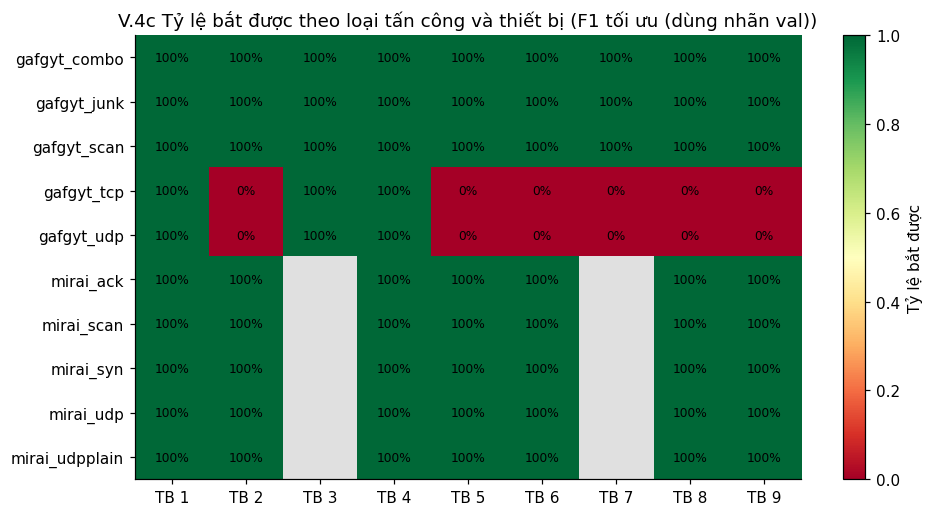

In [15]:
# V.4c bản đồ nhiệt: mọi loại tấn công x mọi thiết bị, theo quy tắc chính
H = L[(L.rule == MAIN_RULE) & (L.kind != "benign")].pivot_table(index="kind", columns="device_id", values="row_rate")
cmap = plt.get_cmap("RdYlGn").copy(); cmap.set_bad("#e0e0e0")          # ô xám = thiết bị không có loại tấn công này
fig, ax = plt.subplots(figsize=(9, 4.8))
im = ax.imshow(np.ma.masked_invalid(H.values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(H.shape[1]), [f"TB {c}" for c in H.columns]); ax.set_yticks(range(H.shape[0]), H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if not np.isnan(H.values[i, j]):
            ax.text(j, i, f"{H.values[i, j]:.0%}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, label="Tỷ lệ bắt được")
ax.set_title(f"V.4c Tỷ lệ bắt được theo loại tấn công và thiết bị ({RULE_LABEL[MAIN_RULE]})")
fig.tight_layout(); fig.savefig(f"{OUT}/{MODEL_NAME}_ban_do_nhiet.png", dpi=150); plt.show()

### 5. Biểu đồ đánh đổi giữa bắt được và báo nhầm

Mỗi quy tắc ngưỡng là một điểm. Trục ngang là báo nhầm (càng sang trái càng tốt), trục dọc là bắt được (càng lên cao càng tốt). Điểm lý tưởng nằm ở góc trên bên trái.
Chấm tròn là mọi loại tấn công, chấm vuông là riêng tcp/udp.

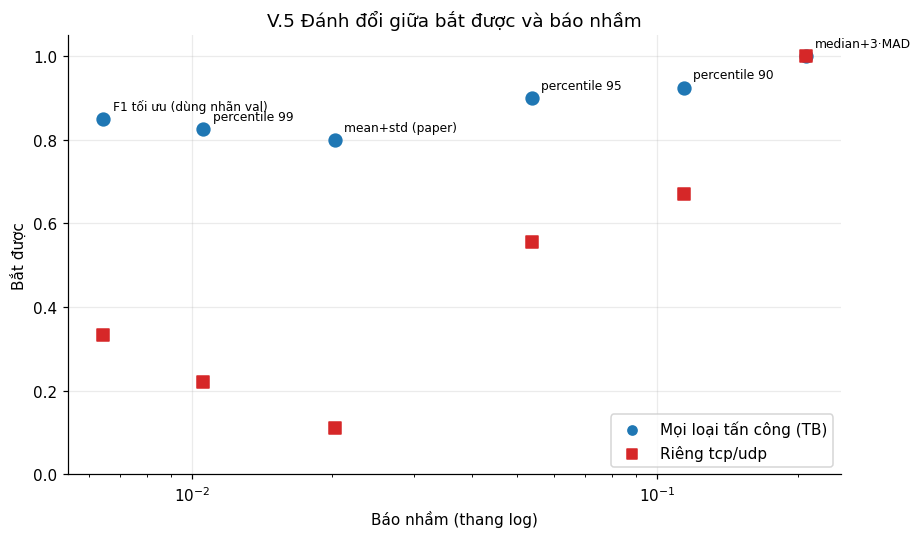

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for r in RULES:
    x = SUM.loc[r, "fpr"]
    ax.scatter(x, SUM.loc[r, "recall_macro"], s=70, marker="o", color="tab:blue", zorder=3)
    ax.scatter(x, SUM.loc[r, "recall_tcp_udp"], s=70, marker="s", color="tab:red", zorder=3)
    ax.annotate(RULE_LABEL[r], (x, SUM.loc[r, "recall_macro"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.scatter([], [], marker="o", color="tab:blue", label="Mọi loại tấn công (TB)")
ax.scatter([], [], marker="s", color="tab:red", label="Riêng tcp/udp")
ax.set_xscale("log"); ax.set_ylim(0, 1.05)
ax.set_xlabel("Báo nhầm (thang log)"); ax.set_ylabel("Bắt được"); ax.legend(loc="lower right")
ax.set_title("V.5 Đánh đổi giữa bắt được và báo nhầm")
fig.tight_layout(); fig.savefig(f"{OUT}/{MODEL_NAME}_danh_doi.png", dpi=150); plt.show()

### 6. Phân phối điểm bất thường

Mỗi biểu đồ là một thiết bị (đổi danh sách `DEV_PLOT` ở mục I.2 để xem thiết bị khác). Trục ngang là điểm bất thường (thang log), các vạch đứng là ngưỡng.
Phần tấn công nằm càng xa bên phải benign thì càng dễ tách. Nếu chồng lên benign thì khó bắt mà không báo nhầm.

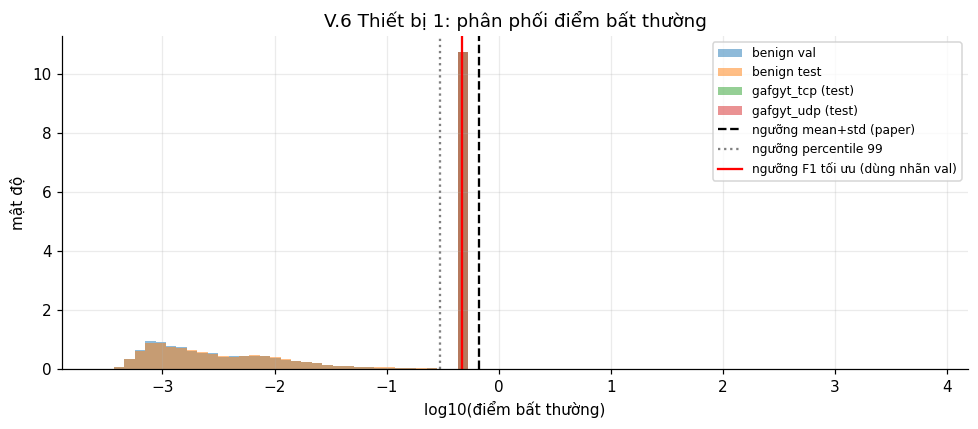

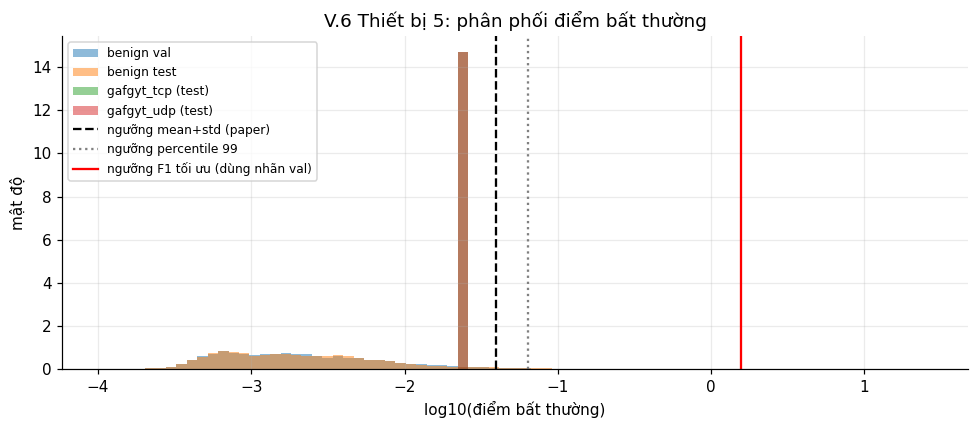

In [17]:
THR = L.drop_duplicates(["device_id", "rule"]).set_index(["device_id", "rule"])["thr"]
for d in [x for x in DEV_PLOT if x in DEVICES]:
    kind, split, s = load_scores(d); role = make_roles(kind, split)
    groups = [("benign val", role == "b_val"), ("benign test", role == "b_test"),
              ("gafgyt_tcp (test)", (kind == "gafgyt_tcp") & (role == "a_test")),
              ("gafgyt_udp (test)", (kind == "gafgyt_udp") & (role == "a_test"))]
    lg = {name: np.log10(s[m] + 1e-9) for name, m in groups if m.any()}
    bins = np.linspace(min(v.min() for v in lg.values()), max(v.max() for v in lg.values()), 80)
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, v in lg.items():
        ax.hist(v, bins, alpha=0.5, density=True, label=name)
    for rule, ls, col in (("mean_std", "--", "black"), ("p99", ":", "gray"), ("f1_opt", "-", "red")):
        ax.axvline(np.log10(THR[(d, rule)]), color=col, ls=ls, label=f"ngưỡng {RULE_LABEL[rule]}")
    ax.set_xlabel("log10(điểm bất thường)"); ax.set_ylabel("mật độ"); ax.legend(fontsize=8)
    ax.set_title(f"V.6 Thiết bị {d}: phân phối điểm bất thường")
    fig.tight_layout(); fig.savefig(f"{OUT}/{MODEL_NAME}_phan_phoi_dev{d}.png", dpi=150); plt.show()

### 7. Bỏ phiếu theo cửa sổ (cách của paper)

Paper không quyết định theo từng dòng mà theo **cửa sổ**: một nhóm dòng liên tiếp, báo tấn công khi quá nửa số dòng trong nhóm vượt ngưỡng. Cỡ cửa sổ nhỏ nhất cho **0% báo nhầm trên val** được chọn.
- **V.7a**: kết quả cho quy tắc của paper (`mean+std`), từng thiết bị. `Chạm trần` nghĩa là cỡ cửa sổ lên tới giới hạn `WS_MAX` mà vẫn chưa đạt 0% báo nhầm.
- **V.7b**: so sánh các quy tắc ngưỡng theo cửa sổ.

In [18]:
W = L[L.rule == "mean_std"]
rows = []
for d, g in W.groupby("device_id"):
    ben, att = g[g.kind == "benign"].iloc[0], g[g.kind != "benign"]
    rows.append({"Thiết bị": d, "Cỡ cửa sổ": int(ben.ws), "Đạt 0% báo nhầm trên val": "có" if ben.ws_ok else "KHÔNG (chạm trần)",
                 "Báo nhầm (cửa sổ)": ben.window_rate, "Cửa sổ tấn công bị báo (TB)": att.window_rate.mean(),
                 "Loại không có cửa sổ nào bị báo": ", ".join(att[~att.detected].kind) or "không"})
WT = pd.DataFrame(rows).set_index("Thiết bị")
show(WT, pct=["Báo nhầm (cửa sổ)", "Cửa sổ tấn công bị báo (TB)"], grad=["Cửa sổ tấn công bị báo (TB)"], vmin=0, vmax=1,
     caption="V.7a Bỏ phiếu theo cửa sổ, quy tắc mean+std của paper")

rows = []
for rule in RULES:
    g = L[L.rule == rule]; att, ben = g[g.kind != "benign"], g[g.kind == "benign"]
    rows.append({"Quy tắc ngưỡng": RULE_LABEL[rule], "Báo nhầm (cửa sổ, TB)": ben.window_rate.mean(),
                 "Cửa sổ tấn công bị báo (TB)": att.window_rate.mean(),
                 "Cặp không cửa sổ nào báo": int((~att.detected).sum()), "Thiết bị chạm trần cỡ cửa sổ": int((~ben.ws_ok).sum())})
WR = pd.DataFrame(rows).set_index("Quy tắc ngưỡng")
WR.to_csv(f"{OUT}/{MODEL_NAME}_cua_so.csv")
show(WR, pct=["Báo nhầm (cửa sổ, TB)", "Cửa sổ tấn công bị báo (TB)"], grad=["Cửa sổ tấn công bị báo (TB)"], vmin=0, vmax=1,
     caption="V.7b So sánh các quy tắc ngưỡng theo cửa sổ")

,Cỡ cửa sổ,Đạt 0% báo nhầm trên val,Báo nhầm (cửa sổ),Cửa sổ tấn công bị báo (TB),Loại không có cửa sổ nào bị báo
Thiết bị,,,,,
1,74,có,0.5%,80.0%,"gafgyt_tcp, gafgyt_udp"
2,154,có,0.0%,80.0%,"gafgyt_tcp, gafgyt_udp"
3,2,có,0.0%,60.0%,không
4,104,có,0.1%,100.0%,không
5,158,có,0.0%,80.0%,"gafgyt_tcp, gafgyt_udp"
6,200,KHÔNG (chạm trần),2.6%,80.0%,"gafgyt_tcp, gafgyt_udp"
7,200,KHÔNG (chạm trần),0.6%,60.0%,"gafgyt_tcp, gafgyt_udp"
8,52,có,0.2%,80.0%,"gafgyt_tcp, gafgyt_udp"
9,46,có,0.0%,80.0%,"gafgyt_tcp, gafgyt_udp"


,"Báo nhầm (cửa sổ, TB)",Cửa sổ tấn công bị báo (TB),Cặp không cửa sổ nào báo,Thiết bị chạm trần cỡ cửa sổ
Quy tắc ngưỡng,,,,
mean+std (paper),0.4%,80.0%,14,2
percentile 99,0.1%,82.5%,13,1
percentile 95,0.9%,90.0%,8,5
percentile 90,2.4%,92.5%,6,9
median+3·MAD,6.5%,100.0%,0,9
F1 tối ưu (dùng nhãn val),0.1%,85.0%,7,0


## VI. Tóm tắt và hạn chế

### 1. Tóm tắt nhanh

In [19]:
m, p = SUM.loc[MAIN_RULE], SUM.loc["p99"]
note(f"""
**Quy tắc chính: {RULE_LABEL[MAIN_RULE]}** (kết quả trên nửa test, gộp {len(DEVICES)} thiết bị)

- Bắt được trung bình các loại tấn công: **{m.recall_macro:.1%}**, riêng tcp/udp: **{m.recall_tcp_udp:.1%}**
- Báo nhầm benign: **{m.fpr:.2%}**
- Báo đúng khi cảnh báo (tỷ lệ tấn công 5%): **{m.precision:.1%}**, F1 = **{m.f1:.3f}**
- Cặp (thiết bị, loại) bị bỏ sót hoàn toàn: **{int(m.n_missed)}/{int(m.n_pairs)}**

Để so sánh, quy tắc percentile 99: bắt được **{p.recall_macro:.1%}** (tcp/udp **{p.recall_tcp_udp:.1%}**), báo nhầm **{p.fpr:.2%}**, F1 = **{p.f1:.3f}**.
""")


**Quy tắc chính: F1 tối ưu (dùng nhãn val)** (kết quả trên nửa test, gộp 9 thiết bị)

- Bắt được trung bình các loại tấn công: **85.0%**, riêng tcp/udp: **33.3%**
- Báo nhầm benign: **0.65%**
- Báo đúng khi cảnh báo (tỷ lệ tấn công 5%): **87.4%**, F1 = **0.862**
- Cặp (thiết bị, loại) bị bỏ sót hoàn toàn: **3/80**

Để so sánh, quy tắc percentile 99: bắt được **82.5%** (tcp/udp **22.0%**), báo nhầm **1.06%**, F1 = **0.814**.


### 2. File đã lưu

In [20]:
files = sorted(f for f in os.listdir(OUT) if f.startswith(MODEL_NAME + "_"))
listing = pd.DataFrame({"File": files, "Kích thước (KB)": [round(os.path.getsize(f"{OUT}/{f}") / 1024, 1) for f in files]}).set_index("File")
show(listing, digits=1, caption=f"VI.2 Kết quả đã lưu trong {OUT}")
print("Mô hình và scaler:", MODELS)
print("Điểm bất thường từng thiết bị:", SCORES)

,Kích thước (KB)
File,
ae_auc.csv,1.7
ae_ban_do_nhiet.png,74.5
ae_chi_tiet.csv,40.3
ae_cua_so.csv,0.5
ae_danh_doi.png,55.7
ae_huan_luyen.csv,0.7
ae_loss_curve.png,255.4
ae_loss_log.csv,85.5
ae_phan_phoi_dev1.png,56.6


Mô hình và scaler: /kaggle/working/models/ae
Điểm bất thường từng thiết bị: /kaggle/working/scores


### 3. Cách đọc và hạn chế

**Cách đọc nhanh:** mở bảng V.2, so hàng `F1 tối ưu` với hàng `percentile 99`. Nếu F1 tăng và báo nhầm vẫn thấp thì việc chọn ngưỡng riêng từng thiết bị có ích. Sau đó xem V.4 để biết hai loại tcp/udp có được bắt không, và V.5 để thấy cái giá phải trả.

**Hạn chế cần ghi trong báo cáo:**
1. Quy tắc `F1 tối ưu` dùng nhãn tấn công của nửa `val` để chọn ngưỡng, nên đây là kết quả **bán giám sát**, không so trực tiếp với các quy tắc chỉ dùng benign.
2. Nửa `val` và nửa `test` của tấn công đều lấy từ cùng một file tấn công. Kết quả cho biết mô hình bắt được loại tấn công **đã từng thấy**, chưa chứng minh bắt được tấn công hoàn toàn mới.
3. Số liệu là một lần chạy với một seed. Chênh lệch nhỏ giữa các quy tắc có thể chỉ là dao động.
4. Tính theo thiết bị: thiết bị có loss val cao bất thường (mục IV.2) nên xem riêng trước khi kết luận.